<a href="https://colab.research.google.com/github/4ndrese16/perros-vs-gatos/blob/main/examples/vision/ipynb/image_classification_from_scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Image classification from scratch

**Author:** [fchollet](https://twitter.com/fchollet)<br>
**Date created:** 2020/04/27<br>
**Last modified:** 2023/11/09<br>
**Description:** Training an image classifier from scratch on the Kaggle Cats vs Dogs dataset.

## Introduction

This example shows how to do image classification from scratch, starting from JPEG
image files on disk, without leveraging pre-trained weights or a pre-made Keras
Application model. We demonstrate the workflow on the Kaggle Cats vs Dogs binary
classification dataset.

We use the `image_dataset_from_directory` utility to generate the datasets, and
we use Keras image preprocessing layers for image standardization and data augmentation.

## Setup

In [11]:
import os
import numpy as np
import keras
from keras import layers
from tensorflow import data as tf_data
import matplotlib.pyplot as plt

## Load the data: the Cats vs Dogs dataset

### Raw data download

First, let's download the 786M ZIP archive of the raw data:

In [12]:
!curl -O https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  786M  100  786M    0     0  70.0M      0  0:00:11  0:00:11 --:--:-- 77.5M


In [13]:
!unzip -q kagglecatsanddogs_5340.zip
!ls

 CDLA-Permissive-2.0.pdf      save_at_22.keras	 save_at_3.keras
 kagglecatsanddogs_5340.zip   save_at_23.keras	 save_at_40.keras
 model.png		      save_at_24.keras	 save_at_41.keras
 PetImages		      save_at_25.keras	 save_at_42.keras
'readme[1].txt'		      save_at_26.keras	 save_at_43.keras
 sample_data		      save_at_27.keras	 save_at_44.keras
 save_at_10.keras	      save_at_28.keras	 save_at_45.keras
 save_at_11.keras	      save_at_29.keras	 save_at_46.keras
 save_at_12.keras	      save_at_2.keras	 save_at_47.keras
 save_at_13.keras	      save_at_30.keras	 save_at_48.keras
 save_at_14.keras	      save_at_31.keras	 save_at_49.keras
 save_at_15.keras	      save_at_32.keras	 save_at_4.keras
 save_at_16.keras	      save_at_33.keras	 save_at_50.keras
 save_at_17.keras	      save_at_34.keras	 save_at_5.keras
 save_at_18.keras	      save_at_35.keras	 save_at_6.keras
 save_at_19.keras	      save_at_36.keras	 save_at_7.keras
 save_at_1.keras	      save_at_37.keras	 save_at_8.keras
 save_at_2

Now we have a `PetImages` folder which contain two subfolders, `Cat` and `Dog`. Each
subfolder contains image files for each category.

In [14]:
!ls PetImages

Cat  Dog


### Filter out corrupted images

When working with lots of real-world image data, corrupted images are a common
occurence. Let's filter out badly-encoded images that do not feature the string "JFIF"
in their header.

In [15]:
num_skipped = 0
for folder_name in ("Cat", "Dog"):
    folder_path = os.path.join("PetImages", folder_name)
    for fname in os.listdir(folder_path):
        fpath = os.path.join(folder_path, fname)
        try:
            fobj = open(fpath, "rb")
            is_jfif = b"JFIF" in fobj.peek(10)
        finally:
            fobj.close()

        if not is_jfif:
            num_skipped += 1
            # Delete corrupted image
            os.remove(fpath)

print(f"Deleted {num_skipped} images.")

Deleted 1590 images.


## Generate a `Dataset`

In [16]:
image_size = (180, 180)
batch_size = 128

train_ds, val_ds = keras.utils.image_dataset_from_directory(
    "PetImages",
    validation_split=0.2,
    subset="both",
    seed=1337,
    image_size=image_size,
    batch_size=batch_size,
)

Found 23410 files belonging to 2 classes.
Using 18728 files for training.
Using 4682 files for validation.


## Visualize the data

Here are the first 9 images in the training dataset.

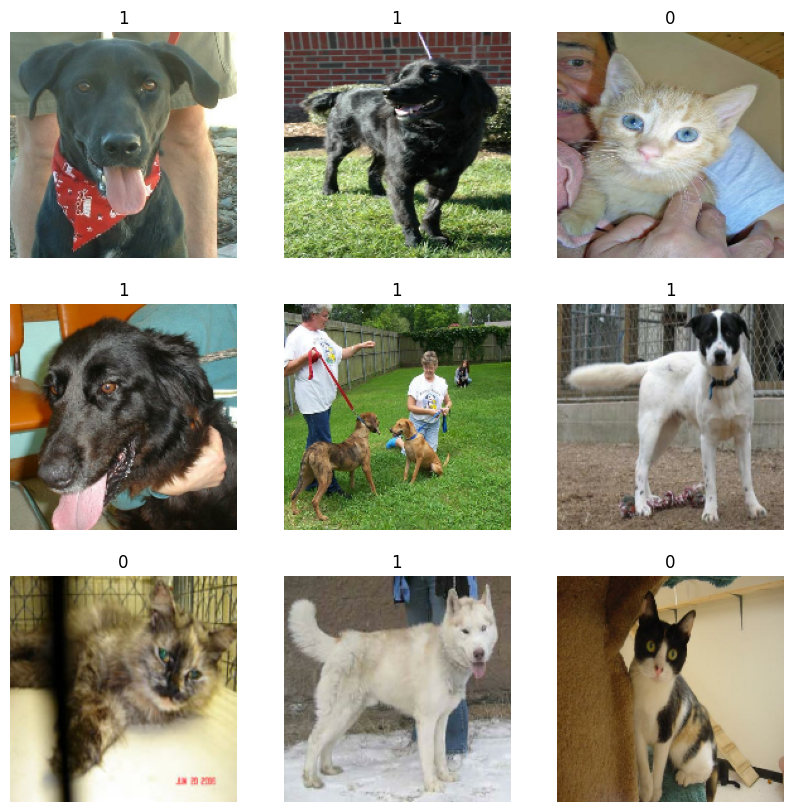

In [17]:
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(np.array(images[i]).astype("uint8"))
        plt.title(int(labels[i]))
        plt.axis("off")

## Using image data augmentation

When you don't have a large image dataset, it's a good practice to artificially
introduce sample diversity by applying random yet realistic transformations to the
training images, such as random horizontal flipping or small random rotations. This
helps expose the model to different aspects of the training data while slowing down
overfitting.

In [18]:
data_augmentation_layers = [
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
]


def data_augmentation(images):
    for layer in data_augmentation_layers:
        images = layer(images)
    return images

Let's visualize what the augmented samples look like, by applying `data_augmentation`
repeatedly to the first few images in the dataset:

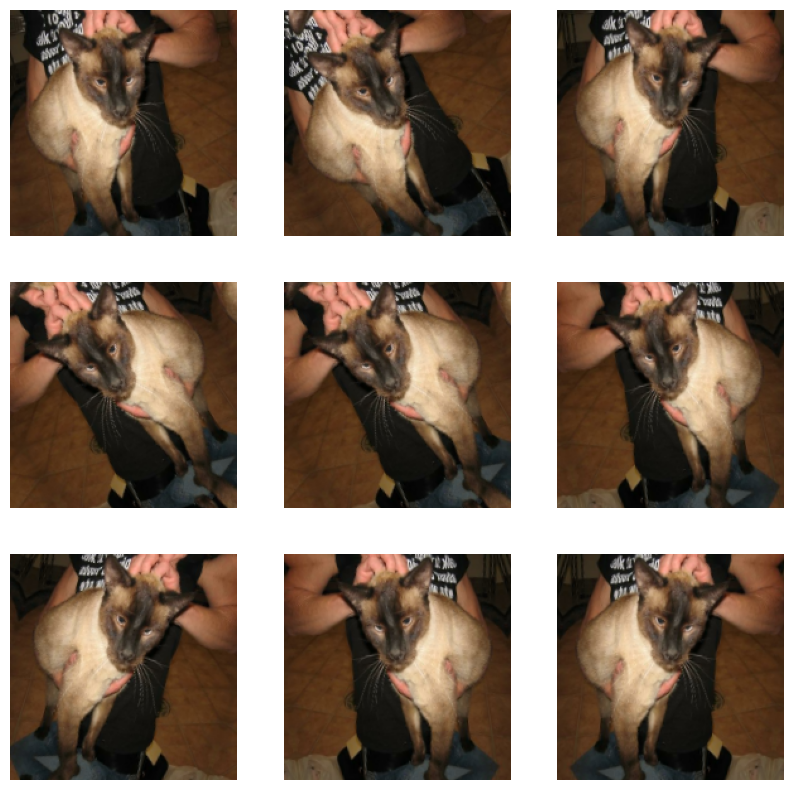

In [19]:
plt.figure(figsize=(10, 10))
for images, _ in train_ds.take(1):
    for i in range(9):
        augmented_images = data_augmentation(images)
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(np.array(augmented_images[0]).astype("uint8"))
        plt.axis("off")

## Standardizing the data

Our image are already in a standard size (180x180), as they are being yielded as
contiguous `float32` batches by our dataset. However, their RGB channel values are in
the `[0, 255]` range. This is not ideal for a neural network;
in general you should seek to make your input values small. Here, we will
standardize values to be in the `[0, 1]` by using a `Rescaling` layer at the start of
our model.

## Two options to preprocess the data

There are two ways you could be using the `data_augmentation` preprocessor:

**Option 1: Make it part of the model**, like this:

```python
inputs = keras.Input(shape=input_shape)
x = data_augmentation(inputs)
x = layers.Rescaling(1./255)(x)
...  # Rest of the model
```

With this option, your data augmentation will happen *on device*, synchronously
with the rest of the model execution, meaning that it will benefit from GPU
acceleration.

Note that data augmentation is inactive at test time, so the input samples will only be
augmented during `fit()`, not when calling `evaluate()` or `predict()`.

If you're training on GPU, this may be a good option.

**Option 2: apply it to the dataset**, so as to obtain a dataset that yields batches of
augmented images, like this:

```python
augmented_train_ds = train_ds.map(lambda x, y: (data_augmentation(x), y))
```

With this option, your data augmentation will happen **on CPU**, asynchronously, and will
be buffered before going into the model.

If you're training on CPU, this is the better option, since it makes data augmentation
asynchronous and non-blocking.

In our case, we'll go with the second option. If you're not sure
which one to pick, this second option (asynchronous preprocessing) is always a solid choice.

## Configure the dataset for performance

Let's apply data augmentation to our training dataset,
and let's make sure to use buffered prefetching so we can yield data from disk without
having I/O becoming blocking:

In [20]:
# Apply `data_augmentation` to the training images.
train_ds = train_ds.map(
    lambda img, label: (data_augmentation(img), label),
    num_parallel_calls=tf_data.AUTOTUNE,
)
# Prefetching samples in GPU memory helps maximize GPU utilization.
train_ds = train_ds.prefetch(tf_data.AUTOTUNE)
val_ds = val_ds.prefetch(tf_data.AUTOTUNE)

## Build a model

We'll build a small version of the Xception network. We haven't particularly tried to
optimize the architecture; if you want to do a systematic search for the best model
configuration, consider using
[KerasTuner](https://github.com/keras-team/keras-tuner).

Note that:

- We start the model with the `data_augmentation` preprocessor, followed by a
 `Rescaling` layer.
- We include a `Dropout` layer before the final classification layer.



In [21]:
def make_model(input_shape, num_classes):
    inputs = keras.Input(shape=input_shape)

    # Entry block
    x = layers.Rescaling(1.0 / 255)(inputs)
    x = layers.Conv2D(128, 3, strides=2, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    previous_block_activation = x  # Set aside residual

    for size in [256, 512, 728]:
        x = layers.Activation("relu")(x)
        x = layers.SeparableConv2D(size, 3, padding="same")(x)
        x = layers.BatchNormalization()(x)

        x = layers.Activation("relu")(x)
        x = layers.SeparableConv2D(size, 3, padding="same")(x)
        x = layers.BatchNormalization()(x)

        x = layers.MaxPooling2D(3, strides=2, padding="same")(x)

        # Project residual
        residual = layers.Conv2D(size, 1, strides=2, padding="same")(
            previous_block_activation
        )
        x = layers.add([x, residual])  # Add back residual
        previous_block_activation = x  # Set aside next residual

    x = layers.SeparableConv2D(1024, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.GlobalAveragePooling2D()(x)
    if num_classes == 2:
        units = 1
    else:
        units = num_classes

    x = layers.Dropout(0.25)(x)
    # We specify activation=None so as to return logits
    outputs = layers.Dense(units, activation=None)(x)
    return keras.Model(inputs, outputs)


model = make_model(input_shape=image_size + (3,), num_classes=2)
keras.utils.plot_model(model, show_shapes=True)

## Train the model

In [22]:
epochs = 25

callbacks = [
    keras.callbacks.ModelCheckpoint("save_at_{epoch}.keras"),
]
model.compile(
    optimizer=keras.optimizers.Adam(3e-4),
    loss=keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=[keras.metrics.BinaryAccuracy(name="acc")],
)
model.fit(
    train_ds,
    epochs=epochs,
    callbacks=callbacks,
    validation_data=val_ds,
)

Epoch 1/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 480s 2s/step - acc: 0.6720 - loss: 0.5906 - val_acc: 0.4957 - val_loss: 0.6969
Epoch 2/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 190s 1s/step - acc: 0.7713 - loss: 0.4585 - val_acc: 0.4957 - val_loss: 0.6927
Epoch 3/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 191s 1s/step - acc: 0.8256 - loss: 0.3667 - val_acc: 0.5032 - val_loss: 0.7057
Epoch 4/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 204s 1s/step - acc: 0.8573 - loss: 0.3111 - val_acc: 0.4957 - val_loss: 0.9778
Epoch 5/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 192s 1s/step - acc: 0.8808 - loss: 0.2727 - val_acc: 0.5701 - val_loss: 0.9740
Epoch 6/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 192s 1s/step - acc: 0.8918 - loss: 0.2444 - val_acc: 0.9056 - val_loss: 0.2349
Epoch 7/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 202s 1s/step - acc: 0.9063 - loss: 0.2154 - val_acc: 0.8052 - val_loss: 0.3744
Epoch 8/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 192s 1s/step - acc: 0.9149 - loss: 0.1962 - val_acc: 0.9178 - val_loss: 0.2077
Epoch 9/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 192s 1s/

We get to >90% validation accuracy after training for 25 epochs on the full dataset
(in practice, you can train for 50+ epochs before validation performance starts degrading).

## Run inference on new data

Note that data augmentation and dropout are inactive at inference time.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step
This image is 99.98% cat and 0.02% dog.
48876/48876 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


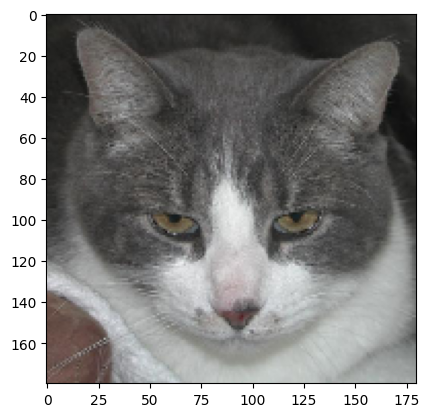

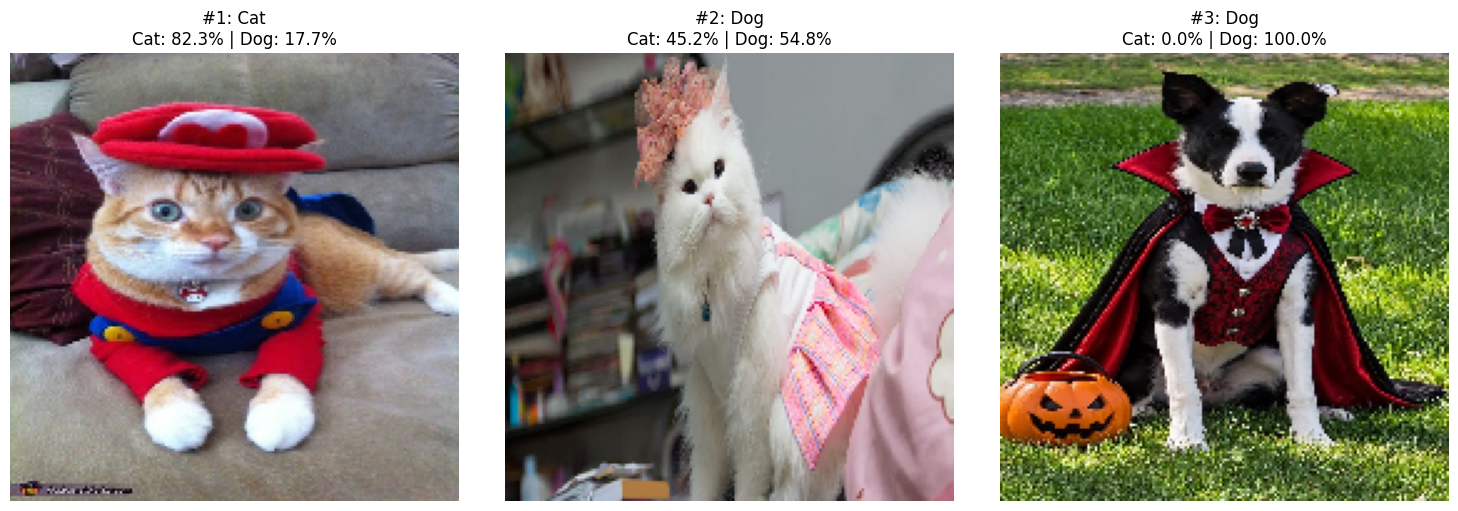

In [36]:
img = keras.utils.load_img("PetImages/Cat/6160.jpg", target_size=image_size)
plt.imshow(img)

img_array = keras.utils.img_to_array(img)
img_array = keras.ops.expand_dims(img_array, 0)  # Create batch axis

predictions = model.predict(img_array)
score = float(keras.ops.sigmoid(predictions[0][0]))
print(f"This image is {100 * (1 - score):.2f}% cat and {100 * score:.2f}% dog.")

urls = [
    "https://i.pinimg.com/474x/ec/8a/d3/ec8ad30487881f9553e6a21a5a0de260.jpg",
    "https://purina.com.ve/sites/default/files/2022-10/conoce-por-que-no-es-buena-idea-usar-un-disfraz-para-tu-gato-01.png",
    "https://i.pinimg.com/originals/36/c9/5e/36c95e4a8f434bb63929c901e1a86ed4.jpg",
]

fig, axes = plt.subplots(1, len(urls), figsize=(15, 5))

for i, url in enumerate(urls):
    # Descarga la imagen en caché local y devuelve la ruta del archivo
    local_path = keras.utils.get_file(origin=url)

    img = keras.utils.load_img(local_path, target_size=image_size)
    img_array = keras.utils.img_to_array(img)
    img_array = keras.ops.expand_dims(img_array, 0)  # Create batch axis

    predictions = model.predict(img_array, verbose=0)
    score = float(keras.ops.sigmoid(predictions[0][0]))

    cat_pct = 100 * (1 - score)
    dog_pct = 100 * score
    label = "Dog" if score >= 0.5 else "Cat"

    axes[i].imshow(img)
    axes[i].set_title(f"#{i+1}: {label}\nCat: {cat_pct:.1f}% | Dog: {dog_pct:.1f}%")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

## Relevant Chapters from Deep Learning with Python
- [Chapter 8: Image classification](https://deeplearningwithpython.io/chapters/chapter08_image-classification)
